In [1]:
import numpy as np
import pandas as pd

# ---- Generate a synthetic bank-loan dataset (no dataset was provided) ----
rng = np.random.default_rng(42)
n = 5000

application_date = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 1400, n), unit="D")
age = rng.integers(21, 66, n)
education = rng.choice(["High School", "Graduate", "Post Graduate", "Doctorate"], n, p=[0.35, 0.40, 0.20, 0.05])
edu_level = pd.Series(education).map({"High School": 0, "Graduate": 1, "Post Graduate": 2, "Doctorate": 3}).values
employment_type = rng.choice(["Salaried", "Self-employed", "Business", "Unemployed"], n, p=[0.55, 0.20, 0.17, 0.08])
home_ownership = rng.choice(["Rent", "Own", "Mortgage"], n, p=[0.45, 0.25, 0.30])
loan_purpose = rng.choice(["Home", "Car", "Education", "Personal", "Business"], n, p=[0.20, 0.25, 0.15, 0.25, 0.15])
employment_years = np.clip(np.round(rng.normal((age - 21) * 0.5, 4)), 0, 40)
employment_years[employment_type == "Unemployed"] = 0
annual_income = np.round(rng.lognormal(np.log(450000) + 0.25 * edu_level + 0.01 * employment_years, 0.55) / 1000) * 1000
annual_income[employment_type == "Unemployed"] = np.round(annual_income[employment_type == "Unemployed"] * 0.3, -3)
credit_score = np.clip(np.round(rng.normal(680 + 3 * employment_years / 4 + 10 * edu_level, 60)), 300, 850)
num_existing_loans = rng.poisson(1.2, n).clip(0, 6)
loan_term_months = rng.choice([12, 24, 36, 60], n, p=[0.15, 0.30, 0.35, 0.20])
purpose_mult = pd.Series(loan_purpose).map({"Home": 2.0, "Car": 1.0, "Education": 0.8, "Personal": 0.5, "Business": 1.5}).values
loan_amount = np.round(annual_income * purpose_mult * (0.6 + (credit_score - 600) / 800) *
                       (loan_term_months / 36) ** 0.5 * rng.lognormal(0, 0.25, n) / 1000) * 1000
loan_amount = np.clip(loan_amount, 20000, None)

# Default risk: low credit score, high loan-to-income, many loans, unemployed, renting, personal loans
ratio = loan_amount / annual_income
z = (-1.6 - (credit_score - 680) / 45 + 0.45 * np.log(ratio) + 0.30 * num_existing_loans
     - 0.04 * employment_years - 0.15 * edu_level
     + 0.6 * (employment_type == "Unemployed") + 0.35 * (home_ownership == "Rent")
     + 0.4 * (loan_purpose == "Personal") + 0.2 * (loan_term_months == 60))
defaulted = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)

df = pd.DataFrame({
    "applicant_id": [f"APP{100000 + i}" for i in range(n)],
    "application_date": application_date.strftime("%Y-%m-%d"),
    "age": age, "education": education, "employment_type": employment_type,
    "employment_years": employment_years, "annual_income": annual_income,
    "home_ownership": home_ownership, "credit_score": credit_score,
    "num_existing_loans": num_existing_loans, "loan_purpose": loan_purpose,
    "loan_term_months": loan_term_months, "loan_amount": loan_amount,
    "defaulted": defaulted})

# Add realistic missing values
for col, k in [("annual_income", 150), ("employment_years", 200), ("credit_score", 250),
               ("employment_type", 120), ("home_ownership", 80)]:
    df.loc[rng.choice(n, k, replace=False), col] = np.nan

df.to_csv("loan_data.csv", index=False)
print("Saved loan_data.csv:", df.shape)

# ---- From here on we work with the CSV, like a trainer-given file ----
df = pd.read_csv("loan_data.csv")
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicates:", df.duplicated().sum())
print("Default rate:", round(df["defaulted"].mean(), 3))

Saved loan_data.csv: (5000, 14)

Column types:
applicant_id              str
application_date          str
age                     int64
education                 str
employment_type           str
employment_years      float64
annual_income         float64
home_ownership            str
credit_score          float64
num_existing_loans      int64
loan_purpose              str
loan_term_months        int64
loan_amount           float64
defaulted               int64
dtype: object

Missing values:
employment_type     120
employment_years    200
annual_income       150
home_ownership       80
credit_score        250
dtype: int64

Duplicates: 0
Default rate: 0.186


## task1 -concepts,splits and leakage

Train 3000 | Val 1000 | Test 1000 (test set put aside)
Default rate - train 0.187 | val 0.186 | test 0.186
Depth    1: train 0.81  val 0.81
Depth    3: train 0.85  val 0.83
Depth    5: train 0.85  val 0.83
Depth   10: train 0.92  val 0.80
Depth None: train 1.00  val 0.74


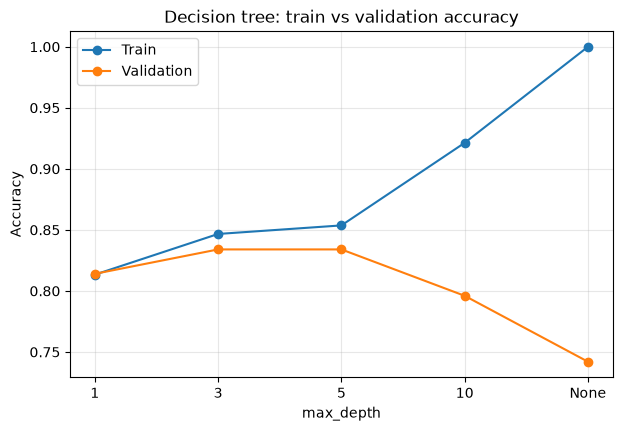

In [2]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

y = df["defaulted"]
X = df.drop(columns=["defaulted", "applicant_id"])       # ID is not a feature

# 60 / 20 / 20 split, stratified, random_state=42
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)   # 0.25 x 80% = 20%

print(f"Train {len(X_train)} | Val {len(X_val)} | Test {len(X_test)} (test set put aside)")
print(f"Default rate - train {y_train.mean():.3f} | val {y_val.mean():.3f} | test {y_test.mean():.3f}")

# Overfitting demo: numeric columns only for Task 1 (full preprocessing comes in Task 2)
num_cols_t1 = ["age", "employment_years", "annual_income", "credit_score",
               "num_existing_loans", "loan_term_months", "loan_amount"]

depths = [1, 3, 5, 10, None]
train_acc, val_acc = [], []
for d in depths:
    tree = make_pipeline(SimpleImputer(strategy="median"),
                         DecisionTreeClassifier(max_depth=d, random_state=42))
    tree.fit(X_train[num_cols_t1], y_train)
    train_acc.append(tree.score(X_train[num_cols_t1], y_train))
    val_acc.append(tree.score(X_val[num_cols_t1], y_val))
    print(f"Depth {str(d):>4}: train {train_acc[-1]:.2f}  val {val_acc[-1]:.2f}")

labels = [str(d) for d in depths]
plt.figure(figsize=(7, 4.5))
plt.plot(labels, train_acc, marker="o", label="Train")
plt.plot(labels, val_acc, marker="o", label="Validation")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision tree: train vs validation accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("t1_overfitting.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ---- 5-fold cross-validation (train + validation data, test set untouched) ----
lr_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                        LogisticRegression(max_iter=1000))
cv_scores = cross_val_score(lr_pipe, X_temp[num_cols_t1], y_temp, cv=5)
print("CV scores:", cv_scores.round(3))
print(f"CV: {cv_scores.mean():.2f} +/- {cv_scores.std():.2f}")

# ---- Data leakage demo ----
# WRONG: learn median + scaling from train AND validation together (= scaling before the split)
both = pd.concat([X_train[num_cols_t1], X_val[num_cols_t1]])
imp_wrong = SimpleImputer(strategy="median").fit(both)
sc_wrong = StandardScaler().fit(imp_wrong.transform(both))
prep = lambda d: sc_wrong.transform(imp_wrong.transform(d[num_cols_t1]))
wrong = LogisticRegression(max_iter=1000).fit(prep(X_train), y_train).score(prep(X_val), y_val)

# RIGHT: pipeline learns median + scaling from TRAIN only, then applies them to validation
right = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(max_iter=1000)) \
            .fit(X_train[num_cols_t1], y_train).score(X_val[num_cols_t1], y_val)

print(f"\nLeaky (scaled before split) val accuracy: {wrong:.3f}")
print(f"Correct (fit on train only)  val accuracy: {right:.3f}")

CV scores: [0.838 0.839 0.841 0.836 0.846]
CV: 0.84 +/- 0.00

Leaky (scaled before split) val accuracy: 0.837
Correct (fit on train only)  val accuracy: 0.837


### Results
- Split (stratified, random_state=42): train 3000 / validation 1000 / test 1000; default rate 18.6% in each. Test set put aside until the final evaluation.
- Overfitting: Depth 1: train 0.81 val 0.81 | Depth 3: 0.85 / 0.83 | Depth 5: 0.85 / 0.83 | Depth 10: 0.92 / 0.80 | Depth None: train 1.00 val 0.74. Depth 3-5 is the sweet spot; deeper trees memorise the training data and get worse on new data.
- Logistic Regression 5-fold CV: 0.84 +/- 0.00 (fold scores 0.836-0.846).

### Data leakage (4 lines)
1. Leaky way: the imputer and scaler learned their medians/means from train + validation together, so information from the evaluation rows leaked into training.
2. Correct way: a Pipeline learns them from the training rows only and just applies them to validation; in cross-validation this is repeated inside every fold.
3. Here both gave 0.837, because medians and means barely change when 1000 extra rows are added - the leak is real but tiny.
4. With stronger leaks (e.g. a column only known after default) the leaky score can look much better than real performance, so preprocessing must always be fitted on training data only.

### Supervised or unsupervised?
- **Spam detection - supervised:** emails are labelled spam / not spam.
- **Customer segmentation - unsupervised:** no labels; the model groups similar customers.
- **House price prediction - supervised:** past sale prices are the labels (regression).
- **Anomaly detection - usually unsupervised:** the model learns what "normal" looks like and flags unusual cases (supervised if past anomalies are labelled).

### ML workflow (7 steps)
1. **Define the problem** - what to predict and how success is measured (e.g. predict loan default, measured by ROC-AUC / recall).
2. **Collect the data** - gather applicant records with the known outcome.
3. **Clean and explore** - fix missing values, wrong types, duplicates; look for patterns.
4. **Split** - train / validation / test, with the test set locked away.
5. **Prepare features and train** - encoding, scaling, new features and models inside a pipeline.
6. **Evaluate and tune** - cross-validation, the right metrics, hyperparameter tuning, threshold choice.
7. **Deploy and monitor** - save the model, predict for new applicants, retrain when data changes.

## Task 2 - Preprocessing, features and pipeline

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, FunctionTransformer

# ---- New features (calculated from each row only, so safe inside the pipeline) ----
def add_features(d):
    d = d.copy()
    date = pd.to_datetime(d["application_date"])
    d["app_year"] = date.dt.year                                   # 1. date decomposition
    d["app_month"] = date.dt.month
    d["app_weekday"] = date.dt.dayofweek
    d["income_to_loan"] = d["annual_income"] / d["loan_amount"]   # 2. interaction
    d["log_income"] = np.log1p(d["annual_income"])                 # 3. log transform (skewed)
    d["log_loan_amount"] = np.log1p(d["loan_amount"])
    return d.drop(columns=["application_date"])

print(add_features(X_train)[["app_year", "app_month", "app_weekday",
                             "income_to_loan", "log_income"]].head())
print(f"\nSkewness of annual_income: before {X_train['annual_income'].skew():.2f} | "
      f"after log {np.log1p(X_train['annual_income']).skew():.2f}")

# ---- Column groups ----
num_cols = ["age", "employment_years", "annual_income", "credit_score", "num_existing_loans",
            "loan_term_months", "loan_amount", "app_year", "app_month", "app_weekday",
            "income_to_loan", "log_income", "log_loan_amount"]
ord_cols = ["education"]                                      # has a real order
ohe_cols = ["employment_type", "home_ownership", "loan_purpose"]   # no order

def make_preprocess(num_imputer):
    return ColumnTransformer([
        ("num", Pipeline([("imputer", num_imputer),
                          ("scaler", StandardScaler())]), num_cols),
        ("ord", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("ordinal", OrdinalEncoder(categories=[["High School", "Graduate",
                                                                  "Post Graduate", "Doctorate"]]))]), ord_cols),
        ("ohe", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), ohe_cols),
    ])

def make_pipeline_full(num_imputer, model):
    return Pipeline([("features", FunctionTransformer(add_features)),
                     ("preprocess", make_preprocess(num_imputer)),
                     ("model", model)])

# ---- Compare SimpleImputer (median) vs KNNImputer, 5-fold CV on raw data ----
for name, imp in [("SimpleImputer (median)", SimpleImputer(strategy="median")),
                  ("KNNImputer (k=5)", KNNImputer(n_neighbors=5))]:
    pipe = make_pipeline_full(imp, LogisticRegression(max_iter=1000))
    s = cross_val_score(pipe, X_temp, y_temp, cv=5)
    print(f"{name:<24} Pipeline CV accuracy: {s.mean():.3f} +/- {s.std():.3f}")

      app_year  app_month  app_weekday  income_to_loan  log_income
1279      2025          4            5        5.291667   13.138239
4063      2023         12            5        1.007712   12.879020
4832      2023          6            4        3.797619   12.672950
4607      2023         11            6        2.654930   12.840003
4335      2023          8            6        1.906310   13.812507

Skewness of annual_income: before 2.52 | after log -0.37
SimpleImputer (median)   Pipeline CV accuracy: 0.842 +/- 0.007
KNNImputer (k=5)         Pipeline CV accuracy: 0.842 +/- 0.007


In [5]:
import joblib

final_pipe = make_pipeline_full(SimpleImputer(strategy="median"), LogisticRegression(max_iter=1000))
final_pipe.fit(X_temp, y_temp)                      # train + validation data (test still locked)

joblib.dump(final_pipe, "loan_pipeline.joblib")
loaded = joblib.load("loan_pipeline.joblib")
print("Pipeline saved and reloaded")

# 3 brand-new RAW applicants - with gaps, text and a date, no manual preprocessing
new_rows = pd.DataFrame({
    "application_date": ["2026-10-12", "2026-09-30", "2026-10-05"],
    "age": [35, 24, 50],
    "education": ["Graduate", "High School", "Post Graduate"],
    "employment_type": ["Salaried", "Unemployed", np.nan],
    "employment_years": [8, 0, np.nan],
    "annual_income": [900000, np.nan, 1500000],
    "home_ownership": ["Own", "Rent", "Mortgage"],
    "credit_score": [760, 540, np.nan],
    "num_existing_loans": [0, 4, 1],
    "loan_purpose": ["Car", "Personal", "Home"],
    "loan_term_months": [36, 60, 24],
    "loan_amount": [600000, 300000, 2500000],
})
print(new_rows)
print("\nPredictions for 3 new rows:", loaded.predict(new_rows))
print("Default probability:       ", loaded.predict_proba(new_rows)[:, 1].round(3))

Pipeline saved and reloaded
  application_date  age      education employment_type  employment_years  \
0       2026-10-12   35       Graduate        Salaried               8.0   
1       2026-09-30   24    High School      Unemployed               0.0   
2       2026-10-05   50  Post Graduate             NaN               NaN   

   annual_income home_ownership  credit_score  num_existing_loans  \
0       900000.0            Own         760.0                   0   
1            NaN           Rent         540.0                   4   
2      1500000.0       Mortgage           NaN                   1   

  loan_purpose  loan_term_months  loan_amount  
0          Car                36       600000  
1     Personal                60       300000  
2         Home                24      2500000  

Predictions for 3 new rows: [0 1 0]
Default probability:        [0.024 0.981 0.055]


### Task 2 results and decisions
- **Missing values:** SimpleImputer (median for numbers, most frequent for text). KNNImputer (k=5) on the numeric columns gave the same CV accuracy (0.842 vs 0.842), because only 2-5% of each column is missing, so the simpler SimpleImputer is kept.
- **Encoding:** `education` has a real order (High School < Graduate < Post Graduate < Doctorate), so OrdinalEncoder with that order; `employment_type`, `home_ownership`, `loan_purpose` have no order, so OneHotEncoder (handle_unknown="ignore" for unseen categories).
- **New features:** date decomposition of `application_date` (year, month, weekday); interaction `income_to_loan` = annual_income / loan_amount (affordability); log transform of `annual_income` (skewness 2.52 → -0.37) and `loan_amount`.
- **No leakage:** the features (FunctionTransformer), imputers, encoders and scaler are all steps inside one Pipeline, so they are re-fitted inside every CV fold.
- **Pipeline CV accuracy: 0.84** (0.842 +/- 0.007).
- **Saved with joblib** and reloaded; predictions for 3 new raw rows: **[0 1 0]** (default probabilities 0.024, 0.981, 0.055).

## Task 3 - Supervised and unsupervised models

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

# ---- 3 classifiers as full pipelines, trained on TRAIN, scored on VALIDATION ----
clf_pipes = {
    "Logistic Regression": make_pipeline_full(SimpleImputer(strategy="median"),
                                              LogisticRegression(max_iter=1000)),
    "Decision Tree":       make_pipeline_full(SimpleImputer(strategy="median"),
                                              DecisionTreeClassifier(max_depth=5, random_state=42)),
    "Random Forest":       make_pipeline_full(SimpleImputer(strategy="median"),
                                              RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                                     oob_score=True, random_state=42, n_jobs=-1)),
}
for name, pipe in clf_pipes.items():
    pipe.fit(X_train, y_train)

print(f"Random Forest OOB score: {clf_pipes['Random Forest'].named_steps['model'].oob_score_:.3f}")

# ---- XGBoost with early stopping on the validation set ----
prep = Pipeline([("features", FunctionTransformer(add_features)),
                 ("preprocess", make_preprocess(SimpleImputer(strategy="median")))])
prep.fit(X_train)                                    # learned from TRAIN only

xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4,
                    early_stopping_rounds=50, eval_metric="logloss", random_state=42)
xgb.fit(prep.transform(X_train), y_train,
        eval_set=[(prep.transform(X_val), y_val)], verbose=False)
print(f"XGBoost early stopping: best number of trees = {xgb.best_iteration + 1} (out of max 1000)")

clf_pipes["XGBoost"] = Pipeline([("prep", prep), ("model", xgb)])   # join back into one pipeline

# ---- Results table: Model | Validation score ----
rows = []
for name, pipe in clf_pipes.items():
    rows.append({"Model": name,
                 "Val accuracy": round(pipe.score(X_val, y_val), 3),
                 "Val ROC-AUC":  round(roc_auc_score(y_val, pipe.predict_proba(X_val)[:, 1]), 3)})
results_t3 = pd.DataFrame(rows)
print("\n", results_t3.to_string(index=False))

Random Forest OOB score: 0.840
XGBoost early stopping: best number of trees = 61 (out of max 1000)

               Model  Val accuracy  Val ROC-AUC
Logistic Regression         0.839        0.809
      Decision Tree         0.817        0.750
      Random Forest         0.834        0.779
            XGBoost         0.836        0.791


In [7]:
# ---- predict_proba vs predict (Logistic Regression, 5 rows) ----
lr_pipe = clf_pipes["Logistic Regression"]
five = X_val.head(5)
print(pd.DataFrame({"P(default)": lr_pipe.predict_proba(five)[:, 1].round(3),
                    "predict":    lr_pipe.predict(five),
                    "actual":     y_val.head(5).values}).to_string(index=False))

# ---- Top 5 features: Random Forest and XGBoost ----
feat_names = [n.split("__", 1)[1] for n in prep.named_steps["preprocess"].get_feature_names_out()]
rf_imp  = pd.Series(clf_pipes["Random Forest"].named_steps["model"].feature_importances_, index=feat_names)
xgb_imp = pd.Series(xgb.feature_importances_, index=feat_names)
print("\nRandom Forest top 5:\n", rf_imp.nlargest(5).round(3).to_string())
print("\nXGBoost top 5:\n", xgb_imp.nlargest(5).round(3).to_string())

 P(default)  predict  actual
      0.061        0       0
      0.357        0       0
      0.033        0       0
      0.312        0       0
      0.225        0       0

Random Forest top 5:
 credit_score        0.343
employment_years    0.064
income_to_loan      0.062
log_loan_amount     0.060
age                 0.059

XGBoost top 5:
 credit_score                  0.201
loan_purpose_Car              0.065
employment_years              0.061
num_existing_loans            0.050
employment_type_Unemployed    0.046


In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score

# Features for regression - must NOT use anything calculated from loan_amount (that would be leakage)
def add_features_reg(d):
    d = d.copy()
    d["app_year"] = pd.to_datetime(d["application_date"]).dt.year
    d["log_income"] = np.log1p(d["annual_income"])
    return d.drop(columns=["application_date", "loan_amount"])

reg_num_cols = ["age", "employment_years", "annual_income", "credit_score",
                "num_existing_loans", "loan_term_months", "app_year", "log_income"]

def make_reg_preprocess():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), reg_num_cols),
        ("ord", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("ordinal", OrdinalEncoder(categories=[["High School", "Graduate",
                                                                  "Post Graduate", "Doctorate"]]))]), ord_cols),
        ("ohe", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), ohe_cols),
    ])

yreg_train = X_train["loan_amount"] / 1e5        # target in lakhs
yreg_val   = X_val["loan_amount"] / 1e5

reg_pipes, coefs = {}, {}
for name, model in [("Linear", LinearRegression()), ("Ridge", Ridge(alpha=10)), ("Lasso", Lasso(alpha=0.1))]:
    pipe = Pipeline([("features", FunctionTransformer(add_features_reg)),
                     ("preprocess", make_reg_preprocess()),
                     ("model", model)]).fit(X_train, yreg_train)
    reg_pipes[name] = pipe
    print(f"{name:<7} validation R2: {r2_score(yreg_val, pipe.predict(X_val)):.3f}")
    names = [n.split("__", 1)[1] for n in pipe.named_steps["preprocess"].get_feature_names_out()]
    coefs[name] = pd.Series(pipe.named_steps["model"].coef_, index=names)

coef_table = pd.DataFrame(coefs).round(2)
print("\nCoefficients (lakhs per 1 std / per category):")
print(coef_table.to_string())
print(f"\nLasso zero coefficients: {(coef_table['Lasso'] == 0).sum()} of {len(coef_table)}")

Linear  validation R2: 0.714
Ridge   validation R2: 0.713
Lasso   validation R2: 0.704

Coefficients (lakhs per 1 std / per category):
                               Linear  Ridge  Lasso
age                              0.08   0.08   0.00
employment_years                 0.00   0.01   0.01
annual_income                    3.75   3.69   3.69
credit_score                     0.58   0.58   0.50
num_existing_loans              -0.02  -0.02  -0.00
loan_term_months                 1.30   1.30   1.20
app_year                         0.07   0.07   0.00
log_income                       0.12   0.18   0.12
education                        0.09   0.09   0.00
employment_type_Business        -0.01  -0.02  -0.00
employment_type_Salaried        -0.01  -0.02  -0.00
employment_type_Self-employed    0.08   0.06   0.00
employment_type_Unemployed      -0.05  -0.02  -0.00
home_ownership_Mortgage          0.12   0.12   0.00
home_ownership_Own              -0.09  -0.09  -0.00
home_ownership_Rent             -

k=2: inertia 5,997 | silhouette 0.446
k=3: inertia 4,453 | silhouette 0.308
k=4: inertia 3,730 | silhouette 0.312
k=5: inertia 3,232 | silhouette 0.275
k=6: inertia 2,897 | silhouette 0.275
k=7: inertia 2,637 | silhouette 0.274
k=8: inertia 2,384 | silhouette 0.279


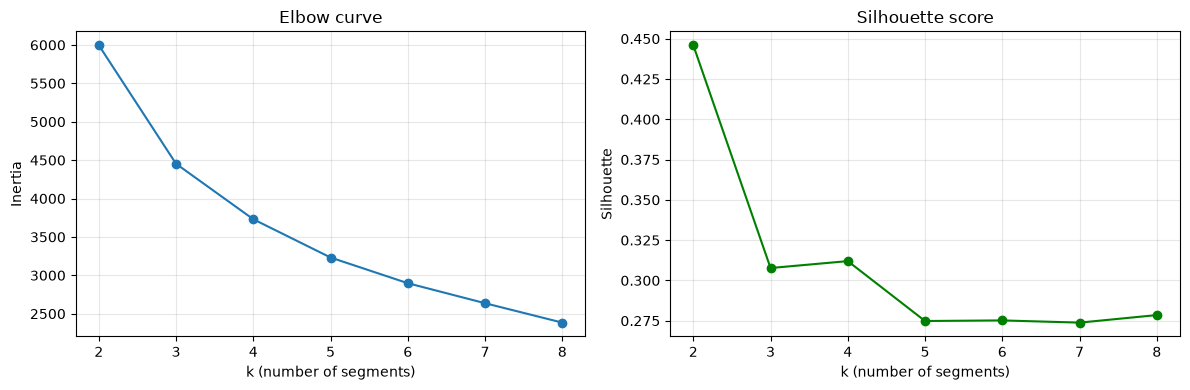

         customers  median_income  median_credit  median_loan  default_rate
segment                                                                    
0             1138       515000.0          650.0     283500.0          0.33
1              466      1399000.0          708.0    1355500.0          0.14
2             1396       544000.0          734.0     342500.0          0.08


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

km_cols = ["annual_income", "credit_score", "loan_amount"]
km_prep = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
Z = km_prep.fit_transform(X_train[km_cols])

ks, inertias, sils = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Z, km.labels_))
    print(f"k={k}: inertia {km.inertia_:,.0f} | silhouette {sils[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertias, marker="o")
axes[0].set_title("Elbow curve")
axes[0].set_xlabel("k (number of segments)")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(ks), sils, marker="o", color="green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k (number of segments)")
axes[1].set_ylabel("Silhouette")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("t3_kmeans.png", dpi=150)
plt.show()

# Describe the segments for k = 3
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z)
seg = X_train[km_cols].assign(segment=km3.labels_, defaulted=y_train.values)
print(seg.groupby("segment").agg(customers=("credit_score", "size"),
                                 median_income=("annual_income", "median"),
                                 median_credit=("credit_score", "median"),
                                 median_loan=("loan_amount", "median"),
                                 default_rate=("defaulted", "mean")).round(2))

In [10]:
# Submission table: Model | Validation score
reg_rows = [{"Model": f"{n} Regression (loan amount)",
             "Val accuracy": None,
             "Val ROC-AUC": None,
             "Val R2": round(r2_score(yreg_val, p.predict(X_val)), 3)}
            for n, p in reg_pipes.items()]
t3_table = pd.concat([results_t3, pd.DataFrame(reg_rows)], ignore_index=True)
print(t3_table.to_string(index=False))
t3_table.to_csv("t3_results.csv", index=False)
print(f"\nRF OOB score: {clf_pipes['Random Forest'].named_steps['model'].oob_score_:.3f} | "
      f"XGBoost stopped at {xgb.best_iteration + 1} trees | "
      f"Lasso zero coefficients: {(coef_table['Lasso'] == 0).sum()} of {len(coef_table)}")

                          Model Val accuracy Val ROC-AUC  Val R2
            Logistic Regression        0.839       0.809     NaN
                  Decision Tree        0.817        0.75     NaN
                  Random Forest        0.834       0.779     NaN
                        XGBoost        0.836       0.791     NaN
Linear Regression (loan amount)         None        None   0.714
 Ridge Regression (loan amount)         None        None   0.713
 Lasso Regression (loan amount)         None        None   0.704

RF OOB score: 0.840 | XGBoost stopped at 61 trees | Lasso zero coefficients: 12 of 21


### Task 3 findings
- **Classifiers** (trained on train, scored on validation - full table in t3_results.csv). Logistic Regression is among the best: default risk rises fairly steadily with credit score and loan-to-income, which suits a linear model. The single Decision Tree is weakest. Random Forest OOB score (~0.84) is close to its validation accuracy.
- **XGBoost early stopping:** up to 1000 trees allowed; training stopped when validation log-loss had not improved for 50 rounds. Its validation score is slightly optimistic because the validation set also chose the stopping point.
- **predict_proba vs predict:** predict applies a fixed 0.5 cut-off, so applicants with 31-36% default risk are still labelled 0. A lower threshold is chosen in Task 4.
- **Top features:** both Random Forest and XGBoost rank **credit_score** first by a wide margin. Random Forest then uses employment_years, income_to_loan and loan amount; XGBoost also uses categories such as loan_purpose and employment_type_Unemployed.
- **Regression (loan amount, in lakhs):** Linear R2 ≈ 0.71, Ridge ≈ 0.71, Lasso ≈ 0.70. Main drivers: loan purpose (Home +, Personal -), annual income and loan term. Ridge shrinks coefficients slightly; **Lasso sets 12 of 21 coefficients to zero** (e.g. age, application year, home ownership), keeping only the strong drivers. Features derived from loan_amount were excluded to avoid leakage.
- **K-Means** on income, credit score and loan amount (scaled): silhouette is highest at k=2 (0.45); the elbow bends around k=3-4, so k=3 was used for business segments:
  - Segment 0 (1138): average income, **low credit (650)**, small loans - **33% default** (high risk)
  - Segment 1 (466): **high income (14 lakhs), large loans (13.6 lakhs)** - 14% default
  - Segment 2 (1396): average income, **high credit (734)**, small loans - **8% default** (low risk)
  K-Means never saw the default label, yet the segments differ strongly in default rate.

## Task 4 - Evaluation and tuning

In [11]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve)

rows = []
for name, pipe in clf_pipes.items():
    pred = pipe.predict(X_val)                       # default threshold 0.5
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    rows.append({"Model": name,
                 "Accuracy":  round(accuracy_score(y_val, pred), 3),
                 "Precision": round(precision_score(y_val, pred, zero_division=0), 3),
                 "Recall":    round(recall_score(y_val, pred), 3),
                 "F1":        round(f1_score(y_val, pred), 3),
                 "TN": tn, "FP": fp, "FN": fn, "TP": tp})
metrics_t4 = pd.DataFrame(rows)
print(metrics_t4.to_string(index=False))

# The "lazy" model: predict 'no default' for everyone
lazy_acc = accuracy_score(y_val, np.zeros(len(y_val)))
print(f"\nAlways predicting 'no default' gives accuracy {lazy_acc:.3f} - and catches 0 defaulters")

              Model  Accuracy  Precision  Recall    F1  TN  FP  FN  TP
Logistic Regression     0.839      0.637   0.312 0.419 781  33 128  58
      Decision Tree     0.817      0.513   0.317 0.392 758  56 127  59
      Random Forest     0.834      0.656   0.226 0.336 792  22 144  42
            XGBoost     0.836      0.662   0.242 0.354 791  23 141  45

Always predicting 'no default' gives accuracy 0.814 - and catches 0 defaulters


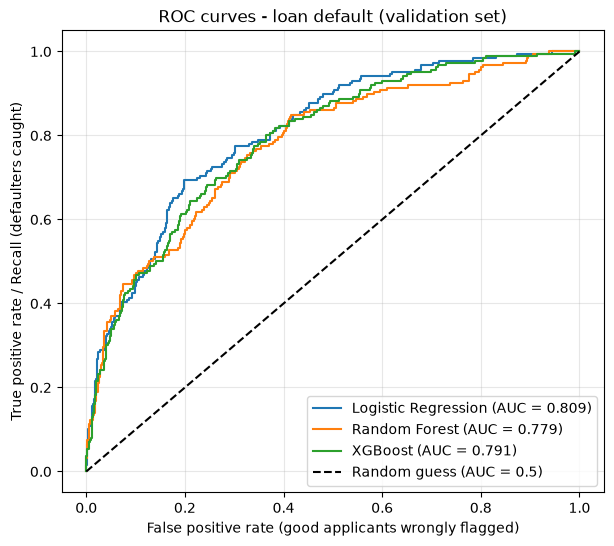

In [12]:
plt.figure(figsize=(7, 6))
for name in ["Logistic Regression", "Random Forest", "XGBoost"]:
    p = clf_pipes[name].predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_val, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False positive rate (good applicants wrongly flagged)")
plt.ylabel("True positive rate / Recall (defaulters caught)")
plt.title("ROC curves - loan default (validation set)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("t4_roc.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
import time
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

# ---- GridSearchCV on Random Forest: 3 parameters (2 x 2 x 3 = 12 combinations) ----
rf_grid = {"model__n_estimators":     [100, 300],
           "model__max_depth":        [None, 10],
           "model__min_samples_leaf": [1, 5, 10]}
start = time.time()
grid = GridSearchCV(make_pipeline_full(SimpleImputer(strategy="median"),
                                       RandomForestClassifier(random_state=42, n_jobs=-1)),
                    rf_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
print(f"Grid search (RF): best CV ROC-AUC {grid.best_score_:.3f} in {time.time() - start:.0f} s")
print("   best params:", grid.best_params_)

# ---- RandomizedSearchCV on XGBoost: 15 random combinations ----
xgb_dist = {"model__n_estimators":     randint(100, 600),
            "model__max_depth":        randint(2, 7),
            "model__learning_rate":    loguniform(0.01, 0.3),
            "model__subsample":        uniform(0.6, 0.4),     # 0.6 to 1.0
            "model__colsample_bytree": uniform(0.6, 0.4)}
start = time.time()
rand = RandomizedSearchCV(make_pipeline_full(SimpleImputer(strategy="median"),
                                             XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=1)),
                          xgb_dist, n_iter=15, cv=5, scoring="roc_auc", random_state=42, n_jobs=-1)
rand.fit(X_train, y_train)
print(f"\nRandomized search (XGB): best CV ROC-AUC {rand.best_score_:.3f} in {time.time() - start:.0f} s")
print("   best params:", {k: round(v, 3) if isinstance(v, float) else v for k, v in rand.best_params_.items()})

Grid search (RF): best CV ROC-AUC 0.785 in 32 s
   best params: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}

Randomized search (XGB): best CV ROC-AUC 0.797 in 23 s
   best params: {'model__colsample_bytree': np.float64(0.933), 'model__learning_rate': np.float64(0.018), 'model__max_depth': 2, 'model__n_estimators': 519, 'model__subsample': np.float64(0.673)}


In [14]:
from sklearn.metrics import precision_recall_curve, mean_absolute_error, mean_squared_error
from sklearn.dummy import DummyRegressor

# ---- 1. Pick the best classifier by validation ROC-AUC ----
candidates = {"Logistic Regression":   clf_pipes["Logistic Regression"],
              "Random Forest (tuned)": grid.best_estimator_,
              "XGBoost (tuned)":       rand.best_estimator_}
val_auc = {n: roc_auc_score(y_val, p.predict_proba(X_val)[:, 1]) for n, p in candidates.items()}
for n, a in val_auc.items():
    print(f"{n:<22} validation ROC-AUC {a:.3f}")
best_name = max(val_auc, key=val_auc.get)
best_model = candidates[best_name]
print(f"-> Best model: {best_name}")

# ---- 2. Threshold for at least 75% recall (chosen on VALIDATION) ----
p_val = best_model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
prec, rec = prec[:-1], rec[:-1]
threshold = thr[np.argmax(np.where(rec >= 0.75, prec, -1))]
pred_val = (p_val >= threshold).astype(int)
print(f"\nThreshold {threshold:.3f}: recall {recall_score(y_val, pred_val):.3f} | "
      f"precision {precision_score(y_val, pred_val):.3f} (validation)")

# ---- 3. Regression vs mean baseline (validation, loan amount in lakhs) ----
print("\nRegression (validation, lakhs):")
reg_models = {"Mean baseline": Pipeline([("model", DummyRegressor(strategy="mean"))]).fit(X_train, yreg_train),
              "Linear Regression": reg_pipes["Linear"]}
for n, m in reg_models.items():
    pr = m.predict(X_val)
    print(f"  {n:<18} MAE {mean_absolute_error(yreg_val, pr):.2f} | "
          f"RMSE {np.sqrt(mean_squared_error(yreg_val, pr)):.2f} | R2 {r2_score(yreg_val, pr):.3f}")

# ---- 4. FINAL: best model evaluated ONCE on the held-out TEST set ----
p_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= threshold).astype(int)
print(f"\nFINAL TEST - Best model: {best_name} | ROC-AUC {roc_auc_score(y_test, p_test):.2f} | "
      f"F1 {f1_score(y_test, pred_test):.2f} | recall {recall_score(y_test, pred_test):.2f} | "
      f"precision {precision_score(y_test, pred_test):.2f}")
print("Test confusion matrix [[TN FP] [FN TP]]:")
print(confusion_matrix(y_test, pred_test))

Logistic Regression    validation ROC-AUC 0.809
Random Forest (tuned)  validation ROC-AUC 0.782
XGBoost (tuned)        validation ROC-AUC 0.804
-> Best model: Logistic Regression

Threshold 0.180: recall 0.774 | precision 0.369 (validation)

Regression (validation, lakhs):
  Mean baseline      MAE 3.97 | RMSE 5.99 | R2 -0.000
  Linear Regression  MAE 1.98 | RMSE 3.21 | R2 0.714

FINAL TEST - Best model: Logistic Regression | ROC-AUC 0.78 | F1 0.47 | recall 0.69 | precision 0.36
Test confusion matrix [[TN FP] [FN TP]]:
[[585 229]
 [ 58 128]]


%%writefile README.md
# Week 2 Assessment - Loan Default Prediction

**Notebook:** `week2_assessment.ipynb` (run top to bottom with Run All)

## Data
No dataset was provided, so `loan_data.csv` (5,000 applicants, 14 columns) was generated with a fixed seed (42).
Target `defaulted` (18.6% default). Includes a date, an ordered column (education), a skewed column (income) and missing values in 5 columns.

## Key decisions
- 60/20/20 stratified split (random_state=42); test set used only once, at the end.
- All preprocessing (new features, imputation, encoding, scaling) is inside one Pipeline, so nothing is fitted outside cross-validation.
- SimpleImputer kept over KNNImputer (same CV score, simpler).
- OrdinalEncoder for education (has an order); OneHotEncoder for other categories.
- Regression features exclude anything derived from loan_amount (avoids leakage).
- ROC-AUC used to compare classifiers (imbalanced data); threshold chosen for ≥ 75% recall.

## Results
| Task | Result |
|---|---|
| Overfitting | Depth 1: train 0.81 / val 0.81 ... Depth None: train 1.00 / val 0.74 |
| CV (Logistic Regression) | 0.84 +/- 0.00 |
| Pipeline CV accuracy | 0.84; predictions for 3 new raw rows: [0 1 0] |
| Classifiers (validation ROC-AUC) | Logistic Regression 0.809, XGBoost 0.791, Random Forest 0.779 |
| Regression (loan amount) | R2 0.714, MAE 1.98 lakhs vs baseline R2 0.00, MAE 3.97 |
| K-Means (k=3) | Segments with 33%, 14% and 8% default rate |
| **Final test** | **Logistic Regression - ROC-AUC 0.78, F1 0.47, recall 0.69, precision 0.36** |

## Files
`loan_data.csv`, `loan_pipeline.joblib`, `t1_overfitting.png`, `t3_kmeans.png`, `t3_results.csv`, `t4_roc.png`